# Sample overview · footprint and paired sky region

**Design:** one horizontal figure, without figure/panel titles. The magnitude
and redshift panels now live in `01b_sample_properties.ipynb`.

**Requested view:** twice the original cutout width: 82 native NISP pixels
(about 24 arcsec), with an aligned 410-pixel JWST image. The field is centred
on COSMOS2020 object `734405` inside validation block `3:2`. Original mosaics are required for the first
extraction; the small GPU cutouts cannot supply these surrounding pixels.

**Data access:** the local package under `data/ready/` and the portable sibling
package are detected automatically. Set `MOSAIC_ROOT` below for mosaics outside
this repository (or set the two explicit file paths). The helper reads real SCI/RMS/DQ, checks
coverage, aligns the footprints and caches the result. No models are run.
Install plotting dependencies if needed: `numpy pandas matplotlib astropy scipy`.


In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Works from the repository root or from paper_figures/.
here = Path.cwd()
workspace = here if (here / 'figure_utils.py').exists() else here / 'paper_figures'
if str(workspace) not in sys.path:
    sys.path.insert(0, str(workspace))
from figure_utils import (ROOT, FIGURES, DATA, COLORS, style, read_json, export,
                          panel, box, arrow, verified_sources, completed_evaluation,
                          run_inventory, sha)
%matplotlib inline
style()
VERSION = 'v07'

In [2]:
import os
from sample_region import extract_region

FIGSIZE = (7.2, 2.65)
# Accepts a project root containing data/NISP-Y/cosmos and data/JWST/cosmos,
# a data directory, or a flat folder containing the two mosaics.
MOSAIC_ROOT = Path(os.environ.get('SUPERNISP_MOSAICS', str(ROOT)))
NISP_PATH = None  # Optional explicit .fits or .fits.gz path.
# Adjacent A4 tile covers the full field; the catalog's A3 tile clips its edge.
JWST_PATH = MOSAIC_ROOT / 'data/JWST/cosmos/mosaic_nircam_f115w_COSMOS-Web_60mas_A4_v0_8_sci.fits'
BLOCK = '3:2'
CENTER_OBJECT_ID = 734405  # Large spiral selected from observed validation images.
NATIVE_SIZE = 41 * 2  # Half the previous field width for a closer view.
REBUILD_REGION = False  # True to replace a cached extraction after changing sources.

manifest_path = DATA / 'manifest.json'
objects_path = DATA / 'objects.csv'
manifest = read_json(manifest_path)
objects = pd.read_csv(objects_path)
assert len(objects) == manifest['accepted']
assert objects.id_classic.is_unique and objects.row.is_unique
assert objects.groupby('split').size().to_dict() == manifest['split_counts']
assert manifest['accepted'] + sum(manifest['rejection_counts'].values()) == manifest['candidates']
zoom_path = FIGURES / 'inputs/sample_region_v06.npz'
zoom_metadata_path = zoom_path.with_suffix('.json')
ready = False
try:
    images, zoom = extract_region(DATA, MOSAIC_ROOT, zoom_path.with_suffix(''),
        block=BLOCK, native_size=NATIVE_SIZE, nisp_path=NISP_PATH,
        jwst_path=JWST_PATH, force=REBUILD_REGION, center_object_id=CENTER_OBJECT_ID)
    ready = True
except FileNotFoundError as error:
    display(Markdown('**Larger region pending original mosaics.** Set `MOSAIC_ROOT` '
                     '(or `NISP_PATH` / `JWST_PATH`) and rerun. No smaller cutout is substituted.'))
    print(error)

# Display-only controls, shared between both bands.
DISPLAY_LOW = -.03
ASINH_SOFTENING = .04  # MJy/sr
DISPLAY_HIGH = 0.9432567954063416  # Retain v05 stretch to isolate the effect of zoom.
# Set to None to use the current field's 99.8th percentile instead.
if ready:
    if DISPLAY_HIGH is None:
        DISPLAY_HIGH = max(float(np.percentile(images['jwst'][images['jwst_valid']], 99.8)), .04)
    field = NATIVE_SIZE * zoom['nisp_pixel_scale_arcsec']
    print(f'{field:.2f} arcsec across; source checksums, sky offsets and masks cached.')


24.33 arcsec across; source checksums, sky offsets and masks cached.


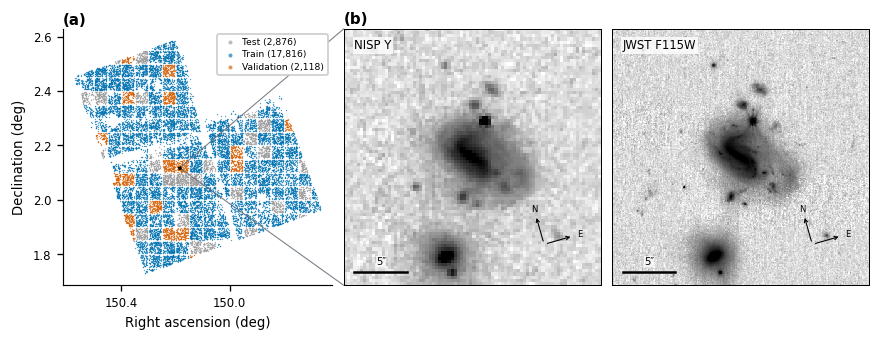

In [3]:
from matplotlib.patches import Polygon, ConnectionPatch
from matplotlib.colors import AsinhNorm

fig, axes = plt.subplots(1, 3, figsize=FIGSIZE, layout='constrained',
                         gridspec_kw={'width_ratios': [1.05, 1, 1]})
fig.get_layout_engine().set(w_pad=.03, h_pad=.03, wspace=.04)
ax = axes[0]
for split in ['test', 'train', 'validation']:
    group = objects[objects.split == split]
    ax.scatter(group.ra, group.dec, s=.65, alpha=.65, color=COLORS[split],
               linewidths=0, rasterized=True,
               label=f"{split.capitalize()} ({len(group):,})")
ax.set(xlabel='Right ascension (deg)', ylabel='Declination (deg)')
ax.invert_xaxis()
ax.set_aspect(1 / np.cos(np.deg2rad(objects.dec.mean())))
ax.legend(loc='upper right', markerscale=3, frameon=True, facecolor='white', framealpha=1,
          fontsize=5.5, handletextpad=.3, borderpad=.4, labelspacing=.35)
ax.xaxis.set_major_locator(plt.MaxNLocator(3))
ax.text(0, 1.02, '(a)', transform=ax.transAxes, fontsize=9, fontweight='bold')
# Only the true 24-arcsec image footprint is outlined on the sky map.
if ready:
    corners = np.asarray(zoom['corners_ra_dec_deg'])
    ax.add_patch(Polygon(corners, closed=True,
        fill=False, edgecolor='black', linewidth=.85, zorder=6))

# Equal-sized image panels fill the row; preserve native NISP sampling.
axes[1].text(0, 1.02, '(b)', transform=axes[1].transAxes, fontsize=9, fontweight='bold')
if ready:
    extent = [-field/2, field/2, -field/2, field/2]
    norm = AsinhNorm(linear_width=ASINH_SOFTENING, vmin=DISPLAY_LOW, vmax=DISPLAY_HIGH)
    cmap = plt.get_cmap('gray_r').copy(); cmap.set_bad('#B0B0B0')
    for view, name, label in [(axes[1], 'nisp', 'NISP Y'), (axes[2], 'jwst', 'JWST F115W')]:
        image = np.ma.array(images[name], mask=~images[name+'_valid'])
        view.imshow(image, origin='lower', extent=extent, interpolation='nearest', cmap=cmap, norm=norm)
        view.text(.04, .96, label, transform=view.transAxes, va='top', fontsize=7,
                  bbox=dict(fc='white', ec='none', alpha=.8, pad=1))
        view.set_xticks([]); view.set_yticks([])
        for spine in view.spines.values(): spine.set_visible(True); spine.set_linewidth(.6)
        bar = 5.  # arcsec
        view.plot([extent[0]+1, extent[0]+1+bar], [extent[2]+1.25]*2, color='black', lw=1.5)
        view.text(extent[0]+1+bar/2, extent[2]+2, '5″', ha='center', fontsize=6,
                  bbox=dict(fc='white', ec='none', alpha=.7, pad=.1))
        origin = np.array([.78, .16])
        for direction, vector in zoom['compass_native_pixel_vectors'].items():
            vector = np.asarray(vector); end = origin + .12*vector/np.linalg.norm(vector)
            view.annotate('', xy=end, xytext=origin, xycoords='axes fraction',
                arrowprops=dict(arrowstyle='->', color='black', lw=.65, mutation_scale=5))
            view.text(*(origin+1.2*(end-origin)), direction, transform=view.transAxes,
                      ha='center', va='center', fontsize=5)
else:
    for view in axes[1:]:
        view.set_axis_off()
        view.text(.5, .5, 'Awaiting original mosaics', transform=view.transAxes,
                  ha='center', va='center', fontsize=8, color='#626A73')
if ready:
    # These WCS corners correspond exactly to the left edge of the NISP view:
    # extraction stores bottom-left, bottom-right, top-right, top-left.
    for corner_index, destination in [(0, (0, 0)), (3, (0, 1))]:
        connector = ConnectionPatch(
            xyA=corners[corner_index], coordsA=axes[0].transData,
            xyB=destination, coordsB=axes[1].transAxes,
            arrowstyle='-', color='#626A73', linewidth=.65, alpha=.85,
            clip_on=False, zorder=2)
        connector.set_in_layout(False)
        axes[0].add_artist(connector)
plt.show()


In [4]:
if ready:
    paths = export(fig, f'fig01_sample_{VERSION}', '01_sample.ipynb',
        [manifest_path, objects_path, zoom_path, zoom_metadata_path, FIGURES/'sample_region.py'],
        dict(figsize=FIGSIZE, layout='three adjacent axes', footprint_annotation='true WCS footprint with two corner connectors',
             scale_bar_arcsec=5,
             display_reference='v05 shared stretch retained', sample_count=len(objects), split_counts=manifest['split_counts'],
             zoom_block=BLOCK, center_object_id=CENTER_OBJECT_ID, zoom_split=zoom['split'],
             selection='Illustrative large spiral; selected by catalog size/brightness and observed morphology in train/validation, without model outputs',
             zoom_field_arcsec=field, display_low=DISPLAY_LOW,
             display_high=DISPLAY_HIGH, asinh_softening=ASINH_SOFTENING,
             test_access='positions/counts only; image footprint contained in validation block'),
        status='sample overview: real matched ~24-arcsec validation region with a large spiral galaxy')
else:
    print('Overview export skipped until the requested larger image field is available.')


Exported: fig01_sample_v07.pdf, fig01_sample_v07.svg, fig01_sample_v07.png


## Working caption

(a) The matched COSMOS galaxy sample, divided into training, validation and
reserved-test spatial blocks. (b) A roughly 24-arcsec field centred on COSMOS2020 galaxy 734405 in the
validation region, shown in Euclid NISP Y and JWST F115W with the same
angular footprint and intensity stretch. The polygon in (a) marks only
the actual image field; two lines connect its corresponding corners to the
left edge of the enlarged NISP view in (b). Scale bars show 5 arcsec; arrows indicate north and
east. NISP retains native sampling; JWST is bilinearly sampled onto a
five-times-finer grid. The images have their local sky estimates subtracted.
Different filters and instrumental PSFs remain part of the comparison.
This illustrative field was chosen for its larger resolved spiral galaxy using
catalog size/brightness and observed morphology; it is not a representative
performance example or a comparison of model predictions.

## Running on the mosaic machine

- Set `SUPERNISP_DATA` before starting Jupyter if the corrected metadata package
  is outside both the sibling location and `data/ready/`, or edit `DATA` in the setup cell.
- Set `MOSAIC_ROOT`, or supply the two explicit band paths. For object `734405` in block `3:2`:
  - `EUC_NIR_W-STK-IMAGE_Y-4911_20250423T231840.182094Z.fits.gz`
  - `mosaic_nircam_f115w_COSMOS-Web_60mas_A4_v0_8_sci.fits`
- Uncompressed NISP `.fits` also works. Compressed/original filenames are
  checked against the package source checksums when available; all source
  files receive a fresh checksum in the extraction record.
- Copy `inputs/sample_region_v06.npz` and `.json` back with the notebook if
  desired. The cached field can then be rendered without the original mosaics.
- Panels formerly c,d are now a separate figure in `01b_sample_properties.ipynb`.
  Final manuscript numbering can follow once we agree on the figure sequence.
